# Grafik Türleri ve Doğru Seçim

Önceki derste görselleştirmenin ilkelerini öğrendik; şimdi sıra bu ilkeleri somut kararlara çevirmekte: elimizdeki veri ve sorumuz için hangi grafik türünü seçmeliyiz? Bu derste altı temel grafik türünü tanıyacak, her birinin hangi soruya cevap verdiğini öğrenecek ve yanlış seçimlerin iletişimi nasıl bozduğunu göreceksin. Kod yine "şimdilik oku" modunda; ortamını 3. derste kuracaksın.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- Veriyi kategorik, sayısal ve zamana bağlı türlerle sınıflandırmak
- Karşılaştırma, dağılım, ilişki, değişim ve parça-bütün sorularını birbirinden ayırmak
- Çizgi, çubuk, histogram, kutu, dağılım ve ısı haritası grafiklerinin hangi soruya cevap verdiğini söylemek
- Bir senaryo için grafik türünü gerekçelendirerek seçmek
- Yanlış grafik seçiminin iletişimi nasıl bozduğunu örneklerle açıklamak

Bu ders, kursun 2. öğrenme çıktısının tamamını ve 10. çıktısının bir bölümünü karşılıyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

Aynı veri, farklı grafik türleriyle bambaşka mesajlar verebilir. "Hangi ürün en çok satıyor?" sorusuna pasta grafiğiyle cevap vermeye çalışmak izleyiciyi açı hesabı yapmaya zorlar; oysa çubuk grafik aynı soruyu tek bakışta yanıtlar. Tersine, aylık satış eğilimini tek tek çubuklarla göstermek değişimin ritmini kaybeder.

Grafik türü seçimi, görselleştirmenin en önemli tasarım kararıdır: önceki dersin ilkeleri (basitlik, vurgu, algısal doğruluk) ancak doğru tür seçildiğinde işe yarar. Bu dersten sonra 7. derste bu türleri kodla üretmeye başlayacağız; şu anki hedefimiz seçim kasını geliştirmek.

## 🔗 Ön Bilgi

- [Giriş: Veri Görselleştirme](01-Visualization-Intro.ipynb): görsel algı (uzunluk vs açı karşılaştırması), beş tasarım ilkesi ve yanıltıcı grafik hataları. Bu derste o kavramlara sık sık döneceğiz.

> **Önemli:** Bu derste de kodu çalıştırman beklenmiyor. Grafikler deftere önceden gömülü; sen işlerine bak. Ortam kurulumu 3. derste, grafik üretimi 7. derste başlıyor.

## 🔍 Birlikte Keşfedelim

Bir öğretmen düşünelim. Sınıfındaki 24 öğrencinin sınav notları şöyle:

55, 62, 67, 48, 73, 85, 91, 58, 76, 69, 82, 95, 61, 57, 70, 78, 66, 88, 52, 74, 79, 63, 71, 90

Öğretmenin sorusu: **"Notlar nasıl dağılıyor? Ortalamanın altında kaç kişi var, notlar dengeli mi yayılmış?"**

**Tahminin:** Bu soruyu cevaplamak için hangi grafik daha işe yarar: her öğrenci için bir çubuk (çubuk grafik), notları aralıklara toplayıp sayan bir grafik (histogram) yoksa her ayı izleyen bir çizgi grafiği? Tahminini ve gerekçeni bu hücreye yaz; sonra aşağıdaki iki grafiği karşılaştır.

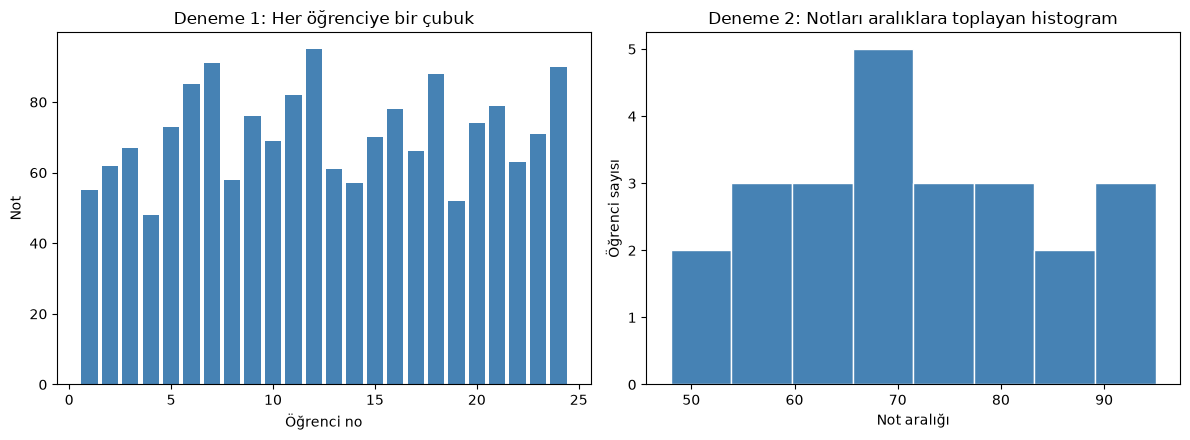

In [1]:
import matplotlib.pyplot as plt

notlar = [55, 62, 67, 48, 73, 85, 91, 58, 76, 69,
          82, 95, 61, 57, 70, 78, 66, 88, 52, 74,
          79, 63, 71, 90]
ogrenci_no = list(range(1, 25))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.bar(ogrenci_no, notlar, color='steelblue')
ax1.set_title('Deneme 1: Her öğrenciye bir çubuk')
ax1.set_xlabel('Öğrenci no')
ax1.set_ylabel('Not')

ax2.hist(notlar, bins=8, color='steelblue', edgecolor='white')
ax2.set_title('Deneme 2: Notları aralıklara toplayan histogram')
ax2.set_xlabel('Not aralığı')
ax2.set_ylabel('Öğrenci sayısı')

plt.tight_layout()
plt.show()

**Gözlem:** Soldaki grafikte 24 ayrı çubuk var ama dağılım hakkında pek bir şey söyleyemiyoruz: öğrenci numarası anlamsız bir sıralama ve göz 24 çubuğu örüntüye çeviremiyor. Sağdaki histogram aynı veriyi 10'luk aralıklara toplayınca soru anında cevaplanıyor: notlar çoğunlukla 55-85 aralığında, 50 altı ve 90 üstü az.

Buradaki ders: grafik seçiminde ilk soru "verim ne?" değil, **"sorum ne?"** olmalı. Şimdi soru türlerini ve onlara uygun grafikleri sistematik olarak inceleyelim.

## 📖 Kavramlar

### Önce veriyi tanı: üç temel veri türü

- **Kategorik veri:** Adlar, gruplar, etiketler. Örnek: şehir, ürün adı, departman. Sayılarla toplama yapılamaz ("Ankara + İzmir" anlamsızdır).
- **Sayısal veri:** Ölçülebilir değerler. Örnek: not, satış adedi, sıcaklık. Aritmetik işlem yapılabilir.
- **Zamana bağlı veri:** Zaman noktasıyla eşleşmiş değerler. Örnek: aylık satış, günlük sıcaklık. Sıralama ve yön (zaman) taşır.

Bir de **soru türleri** var. Grafik seçimini asıl belirleyen budur:

| Soru türü | Sorunun örneği | Tercih edilen grafikler |
|---|---|---|
| Karşılaştırma | "Hangi kategori daha büyük?" | Çubuk |
| Dağılım | "Değerler nasıl yayılıyor?" | Histogram, kutu |
| İlişki | "İki sayısal değişken birlikte mi değişiyor?" | Dağılım (scatter) |
| Değişim (zaman) | "Zamanla nasıl ilerliyor?" | Çizgi |
| Parça-bütün | "Bütün içindeki paylar ne?" | Yığılmış çubuk (tercihen) |
| Yoğunluk tablosu | "İki kategori kesişiminde değer ne?" | Isı haritası |

### Altı temel grafik türü

Aşağıdaki hücre, altı türü küçük örneklerle yan yana gösteriyor. Her panelin altındaki soruyu aklından okuyup grafiğe bak; hangi panel hangi soruya cevap veriyor?

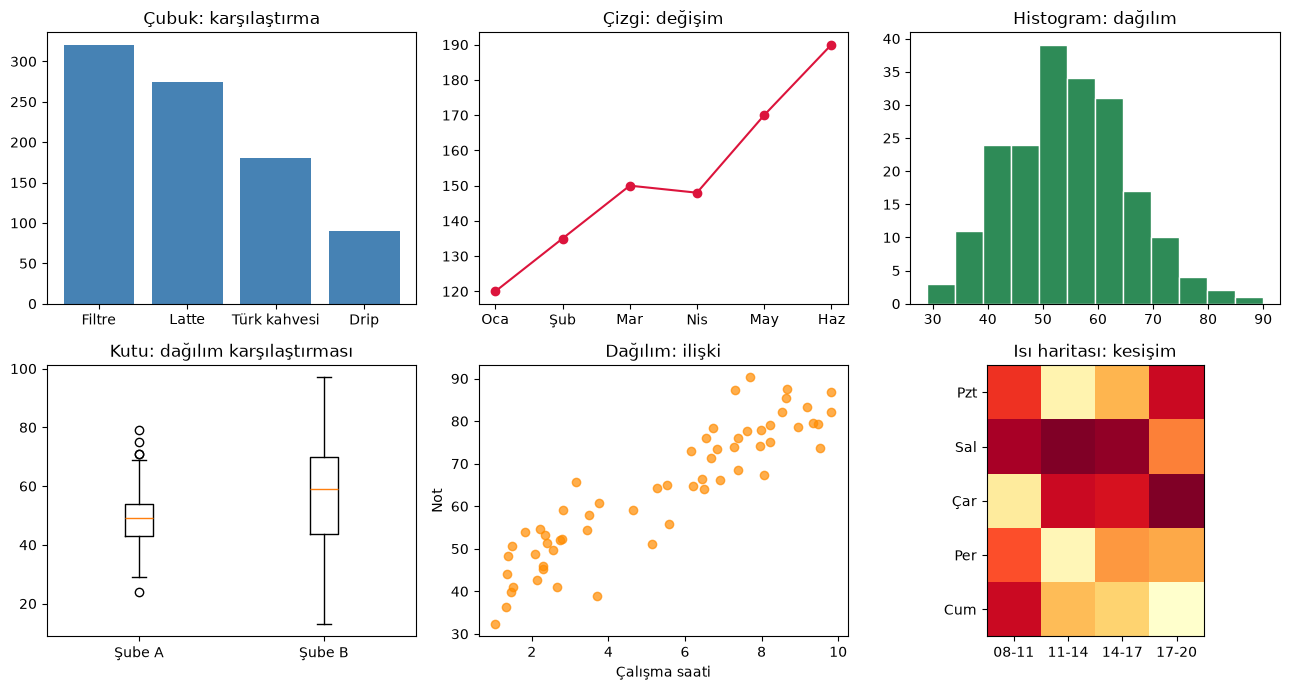

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

# 1) Çubuk: kategoriler arası karşılaştırma
urunler = ['Filtre', 'Latte', 'Türk kahvesi', 'Drip']
adet = [320, 275, 180, 90]
axes[0, 0].bar(urunler, adet, color='steelblue')
axes[0, 0].set_title('Çubuk: karşılaştırma')

# 2) Çizgi: zaman içinde değişim
aylar = ['Oca', 'Şub', 'Mar', 'Nis', 'May', 'Haz']
satis = [120, 135, 150, 148, 170, 190]
axes[0, 1].plot(aylar, satis, marker='o', color='crimson')
axes[0, 1].set_title('Çizgi: değişim')

# 3) Histogram: tek sayısal değişkenin dağılımı
import numpy as np
rng = np.random.default_rng(42)
siparis = rng.normal(loc=55, scale=12, size=200).round()
axes[0, 2].hist(siparis, bins=12, color='seagreen', edgecolor='white')
axes[0, 2].set_title('Histogram: dağılım')

# 4) Kutu: dağılım + medyan + aykırılar
kahve_a, kahve_b = rng.normal(50, 10, 100).round(), rng.normal(55, 18, 100).round()
axes[1, 0].boxplot([kahve_a, kahve_b], tick_labels=['Şube A', 'Şube B'])
axes[1, 0].set_title('Kutu: dağılım karşılaştırması')

# 5) Dağılım (scatter): iki sayısal değişken arasındaki ilişki
calisma = rng.uniform(1, 10, 60)
notx = 40 + 4.5 * calisma + rng.normal(0, 6, 60)
axes[1, 1].scatter(calisma, notx, alpha=0.7, color='darkorange')
axes[1, 1].set_title('Dağılım: ilişki')
axes[1, 1].set_xlabel('Çalışma saati')
axes[1, 1].set_ylabel('Not')

# 6) Isı haritası: iki kategorinin kesişim tablosu
gunler = ['Pzt', 'Sal', 'Çar', 'Per', 'Cum']
saatler = ['08-11', '11-14', '14-17', '17-20']
musteri = rng.integers(30, 120, size=(5, 4))
axes[1, 2].imshow(musteri, cmap='YlOrRd')
axes[1, 2].set_xticks(range(4), saatler)
axes[1, 2].set_yticks(range(5), gunler)
axes[1, 2].set_title('Isı haritası: kesişim')

plt.tight_layout()
plt.show()

Panelleri tek tek yorumlayalım:

- **Çubuk:** Her çubuk bir kategorinin büyüklüğünü taşır; göz uzunlukları karşılaştırır (1. dersin algı konusu). Kategori sayısı ~20'yi geçince yatay çubuk ya da başka bir çözüm düşünülür.
- **Çizgi:** Zaman sırasına dizilmiş noktaları bağlar; eğilim, mevsimsellik ve kırılmalar görünür. Kategorik veriyi çizgiye bağlamak ("Ankara → İzmir → İstanbul" sırası) anlamsızdır.
- **Histogram:** Tek sayısal sütunu aralıklara (bin) dizer; dağılımın şekli (çan, çift tepeli, çarpık) ortaya çıkar. Öğrenci örneğindeki gibi, ham değer listesi yerine aralık sayıları taşır.
- **Kutu:** Aynı dağılım bilgisini beş özet sayıyla verir: medyan, çeyrekler ve aykırı değerler. Gruplar arası dağılım karşılaştırması için histogramdan daha derli topludur.
- **Dağılım grafiği:** Her nokta bir gözlem; iki sayısal değişkenin birlikte değişip değişmediğini (ilişkiyi) gösterir. Nokta sayısı çok artınca yoğunluk ya da hexbin grafikleri devreye girer.
- **Isı haritası:** İki kategorik eksenin kesişimindeki sayıyı renkle kodlar; "hangi gün hangi saatte kalabalık?" gibi soruları tablo okumadan çözer.

### Renk kullanımının temelleri

Renk, 1. derste bir tasarım ilkesiydi; şimdi türlerini ayırt edelim:

- **Kategorik palet:** Birbirinden net ayrışan renkler; her kategoriye bir renk (en fazla 6-7 kategori). Türk kahvesine mavi, latteye turuncu gibi.
- **Sıralı (sürekli) palet:** Düşükten yükseğe koyulaşan tek renk ailesi; ısı haritaları ve sayısal büyüklükler için. Yukarıdaki ısı haritasındaki `YlOrRd` bunun örneği.
- **Vurgu rengi:** Gösterilecek her şey gri, ana mesaj tek renk (1. dersteki Grafik D).

> **Not:** Renk seçerken renk körlüğünü düşün: kırmızı-yeşil ayrımı en yaygın eksikliktir. Kategorik paletlerde kırmızı-turuncu ve mavi tonlu paletler bu açıdan daha güvenlidir. Ayrıca renk yalnızca gerektiğinde bilgi taşımaktır; her çubuğu farklı renk yapmak (1. dersteki soru) süstür.

## 🛠️ Uygulama

Seçim sürecini bir senaryoda uçtan uca izleyelim. **Senaryo:** Kahve zincirinin müdürü, "hafta sonları mı hafta içi mi daha çok kahve satılıyor, ve bu fark şubeden şubeye değişiyor mu?" diye soruyor.

Adımlar: (1) Soru bir karşılaştırma sorusu (hafta içi vs hafta sonu) ve şube başına kırılıyor. (2) Veri kategorik (gün türü, şube) + sayısal (satış). (3) Karar tablosuna göre karşılaştırma → çubuk; şube kırılımı için gruplu çubuk. Kodun "şimdilik oku" modunda nasıl göründüğüne bak:

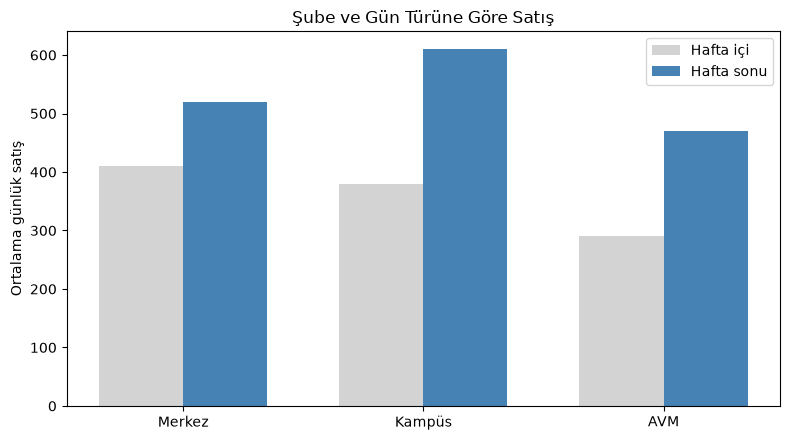

In [3]:
import matplotlib.pyplot as plt
import numpy as np

subeler = ['Merkez', 'Kampüs', 'AVM']
hafta_ici = [410, 380, 290]
hafta_sonu = [520, 610, 470]

x = np.arange(3)
genislik = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - genislik / 2, hafta_ici, genislik, label='Hafta içi', color='lightgray')
ax.bar(x + genislik / 2, hafta_sonu, genislik, label='Hafta sonu', color='steelblue')
ax.set_xticks(x, subeler)
ax.set_ylabel('Ortalama günlük satış')
ax.set_title('Şube ve Gün Türüne Göre Satış')
ax.legend()

plt.tight_layout()
plt.show()

Dikkat et: iki karşılaştırma (gün türü ve şube) tek grafikte yan yana gruplanmış; gri, karşılaştırmanın "taban"ı, mavi ise öne çıkarılan taraf. Renk yine bilgi taşıyor. Müdürün sorusu tek bakışta yanıtlanıyor: hafta sonu her şubede daha kalabalık, en sert fark kampüs şubesinde.

## 🧪 Deneyelim ve Gözlemleyelim

Şimdi tersini yapalım: aynı veriye **yanlış** grafik türünü uygulayıp ne bozulduğunu gözlemleyeceğiz. Aşağıdaki hücrede bir yıllık (12 aylık) satış verisi var; solda yanlış seçim, sağda doğru seçim.

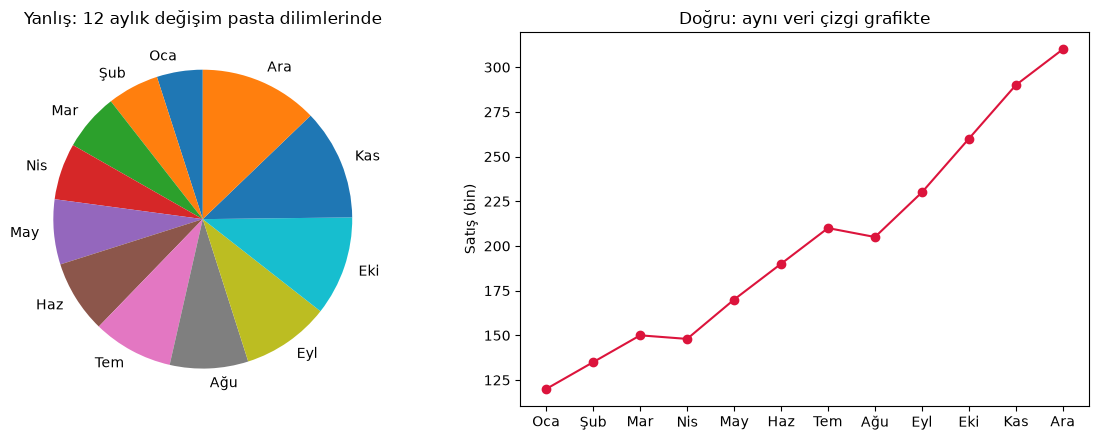

In [4]:
import matplotlib.pyplot as plt

aylar = ['Oca', 'Şub', 'Mar', 'Nis', 'May', 'Haz',
         'Tem', 'Ağu', 'Eyl', 'Eki', 'Kas', 'Ara']
aylik = [120, 135, 150, 148, 170, 190, 210, 205, 230, 260, 290, 310]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.pie(aylik, labels=aylar, startangle=90)
ax1.set_title('Yanlış: 12 aylık değişim pasta dilimlerinde')

ax2.plot(aylar, aylik, marker='o', color='crimson')
ax2.set_title('Doğru: aynı veri çizgi grafikte')
ax2.set_ylabel('Satış (bin)')

plt.tight_layout()
plt.show()

**Gözlem:** Pastada 12 dilimin açılarını kimse karşılaştırmıyor; zaman sırası da kaybolmuş (dilimler bir yönde dönmek dışında "zaman" hissi taşımıyor). Çizgi grafiğe geçince artış ritmi, küçük düşüşler (Nisan, Ağustos) ve yıl sonundaki hızlanma geri geliyor.

İkinci deneme: kategorik veriyi çizgiye bağlamak.

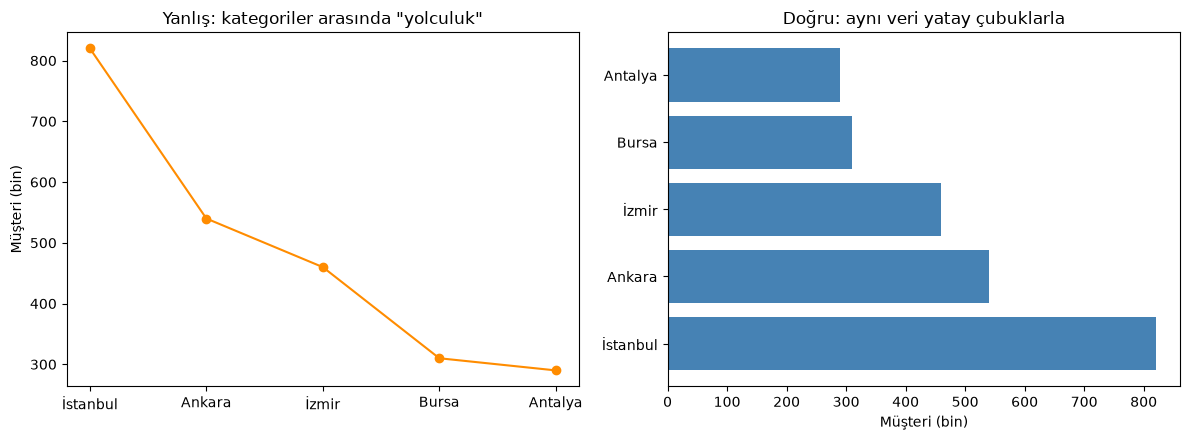

In [5]:
import matplotlib.pyplot as plt

sehirler = ['İstanbul', 'Ankara', 'İzmir', 'Bursa', 'Antalya']
musteri = [820, 540, 460, 310, 290]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(sehirler, musteri, marker='o', color='darkorange')
ax1.set_title('Yanlış: kategoriler arasında "yolculuk"')
ax1.set_ylabel('Müşteri (bin)')

ax2.barh(sehirler, musteri, color='steelblue')
ax2.set_title('Doğru: aynı veri yatay çubuklarla')
ax2.set_xlabel('Müşteri (bin)')

plt.tight_layout()
plt.show()

**Gözlem:** Soldaki çizgi, şehirler arasında var olmayan bir süreç izlenimi veriyor: sanki İstanbul'dan Antalya'ya "gidiliyor" ve arada anlamlı geçişler var. Kategoriler sıralanabilir bir eksen değil; doğru seçim, uzunlukları karşılaştıran çubuk grafik. İki denemenin ortak dersi: **soru türü ile grafik türü uyuşmazsa veri doğru olsa bile mesaj bozulur.**

## 🏋️ Kendin Dene

Aşağıdaki beş senaryo için grafik türünü ve gerekçeni yaz. Karşılaştırma tablosunu ve altı türün özelliklerini kullan:

1. Bir spor salonunun Ocak-Temmuz arası aylık üye sayıları; soru: "Üyelik eğilimi nasıl?"
2. 40 farklı telefon modelinin fiyatları; soru: "Fiyatlar hangi aralıkta yığılıyor?"
3. Öğrencilerin haftalık ders çalışma saati ile not ortalamaları; soru: "Çalışma süresi notu etkiliyor mu?"
4. Dört farklı kargo şirketinin teslim süreleri (her birinden 50'şer ölçüm); soru: "Hangi şirket tutarlı, hangisi değişken?"
5. Bir web sitesinin gün × saat dilimi ziyaretçi sayıları; soru: "Trafiğin sıcak bölgeleri nerede?"

<details>
<summary>İpucu</summary>

Her senaryoda önce verinin türünü (kategorik/sayısal/zaman) sonra sorunun türünü (karşılaştırma/dağılım/ilişki/değişim/kesişim) belirle; sonra karar tablosuna bak.

</details>

## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. "Ankara, İzmir ve Bursa'daki şube satışlarını karşılaştırmak istiyorum." Veri türü, soru türü ve önerdiğin grafik nedir?
2. Histogram ile çubuk grafiğin farkını birer cümleyle açıkla. İkisi de "çubuk" göstermiyor mu?
3. Aylık elektrik faturanı 12 ay boyunca izlemek için hangi grafik türünü seçerdin? Neden pastayı değil?
4. İki sayısal değişken arasındaki ilişkiyi göstermek için hangi grafik kullanılır? Bu grafikte her nokta neyi temsil eder?
5. Isı haritası hangi iki eksen türünün kesişimini göstermeye uygundur? Kendi örnek ver.
6. Kategorik palet ile sıralı (sürekli) palet arasındaki fark nedir? Hangi durumda hangisi kullanılır?

## 🚀 Bağımsız Çalışma

- **Gazete turu:** Bir haber sitesinde bulduğun üç grafiği incele; her biri hangi soru türüne cevap veriyor? Tür seçimi doğru muydu? Yanlışsa doğru türü öner.
- **Galeri gezintisi:** Matplotlib'in resmî grafik galerisini (matplotlib.org/stable/gallery/index.html) on dakika gez. Tanıdık türleri bul, henüz tanımadıklarını not al; kursun ilerleyen derslerinde bazıları karşımıza çıkacak.

## 📚 Daha Fazlasını Öğrenmek

- Matplotlib galerisi: https://matplotlib.org/stable/gallery/index.html
- seaborn örnek galerisi: https://seaborn.pydata.org/examples/index.html
- From Data to Viz (grafik seçim rehberi): https://www.data-to-viz.com

Bu siteler İngilizce; ancak grafik örnekleri dilden bağımsız incelenebilir.

## ✅ Kısa Özet

- Grafik seçiminde ilk adım soruyu sınıflandırmaktır: karşılaştırma, dağılım, ilişki, değişim, parça-bütün ya da kesişim.
- Çubuk → karşılaştırma; çizgi → zamansal değişim; histogram ve kutu → dağılım; dağılım grafiği → ilişki; ısı haritası → iki kategorik eksenin kesişimi.
- Kategorik veri çizgiye bağlanmaz; zaman serisi pastaya dilimlenmez; sayısal dağılım öğrenci öğrenci çubuklanmaz.
- Renkte üç rejim: kategorik palet (ayrışma), sıralı palet (büyüklük), vurgu rengi (tek mesaj).
- Yanlış tür, doğru veriyi bile yanıltıcı ya da anlamsız kılar; seçimini gerekçelendirebiliyorsan doğru yoldasın.

---

[← Önceki ders: Giriş: Veri Görselleştirme](01-Visualization-Intro.ipynb) · [Sıradaki ders: Ortam Kurulumu: Anaconda ve Jupyter →](03-Environment-Setup.ipynb)

## Cevaplar

<details>
<summary>Kendin Dene: beş senaryo</summary>

1. Çizgi — değişim (zaman) sorusu; aylar sıralı bir zaman eksenidir.
2. Histogram — dağılım sorusu; 40 fiyatın aralıklara dizilmesi yığılma bölgelerini gösterir.
3. Dağılım (scatter) — ilişki sorusu; her nokta bir öğrenci, eksenler çalışma saati ve not.
4. Kutu — dağılım karşılaştırması; her kutu bir şirketin 50 ölçümünü özetler, medyan ve değişkenlik karşılaştırılır.
5. Isı haritası — kesişim sorusu; gün ve saat dilimi kategorik eksenleri, hücre renkleri ziyaretçi yoğunluğunu taşır.

</details>

<details>
<summary>Kontrol Et 1</summary>

Veri: kategorik (şehir) + sayısal (satış). Soru: karşılaştırma. Grafik: çubuk (şehir sayısı azsa dikey, adlar uzunsa yatay).

</details>

<details>
<summary>Kontrol Et 2</summary>

Çubuk grafik kategorilerin büyüklüğünü karşılaştırır (her çubuk bir kategori). Histogram tek bir sayısal değişkenin değerlerini aralıklara toplayıp aralıkların gözlem sayısını gösterir (çubuklar aralık temsil eder, kategori değil).

</details>

<details>
<summary>Kontrol Et 3</summary>

Çizgi grafik: 12 ay sıralı bir zaman eksenidir, çizgi değişimin ritmini taşır. Pastada açı karşılaştırması gerektiği ve zaman sırası kaybolduğu için uygun değil.

</details>

<details>
<summary>Kontrol Et 4</summary>

Dağılım (scatter) grafiği. Her nokta tek bir gözlemi temsil eder: yatay konumu birinci değişkendeki değerini, dikey konumu ikinci değişkendeki değerini gösterir.

</details>

<details>
<summary>Kontrol Et 5</summary>

İki kategorik eksenin kesişimi. Örnek: gün × saat dilimi ziyaretçi sayısı, ya da şehir × ürün satışları.

</details>

<details>
<summary>Kontrol Et 6</summary>

Kategorik palet birbirinden net ayrışan renklerden oluşur ve kategorileri ayırt eder (en fazla 6-7 kategori). Sıralı palet tek renk ailesinde açıktan koyuya gider ve sayısal büyüklüğü kodlar; ısı haritalarında ve süreklilik gerektiren durumlarda kullanılır.

</details>